# Modelo de boca: abierta / cerrada

Decide si la boca está **abierta o cerrada**. 

En el juego, mantener la boca abierta **dispara**.

**Datos**
* Recortes de boca de 64×64 (`datasets/boca_recortes`) obtenidos con MediaPipe en el cuaderno `VC_P5_gestos_datasets.ipynb` a partir del **Drowsiness dataset** de Kaggle (clases *yawn* → `abierta`, *no_yawn* → `cerrada`). 

* Son fotogramas de vídeos de conductores, así que hay **muchas imágenes de cada persona** y la misma persona aparece en las dos clases.

**Métodos comparados**
1. Píxeles + KNN (referencia mínima)
2. HOG + SVM
3. LBP + SVM
4. CNN pequeña (en color, con aumento de datos)
5. **MediaPipe `jawOpen`** - puntuación de apertura de mandíbula que MediaPipe ya calcula.

In [2]:
import os
import numpy as np
import matplotlib.pyplot as plt
import cv2
from collections import Counter
from skimage.feature import hog, local_binary_pattern
from sklearn.cluster import AgglomerativeClustering
from sklearn.model_selection import StratifiedGroupKFold
from sklearn.metrics import ConfusionMatrixDisplay

from utilidades_gestos import (carga_dataset, kfold_agrupado, tabla_resultados, metricas, f1_medio,
                               mide_latencia, ModeloGesto, guarda_resumen)

CLASES = ['cerrada', 'abierta'] # etiqueta 1 = abierta (clase positiva)
TAM = 64
ECUALIZAR = True
CARPETA = 'datasets/boca_recortes'
ORIGINALES = 'datasets/boca'    
FIGURAS = 'figuras'

---

## 1. Agrupación aproximada por persona

En el k-fold, si fotogramas casi idénticos de una misma persona caen unos en entrenamiento y otros en test, el modelo "reconoce" a la persona en lugar de aprender el gesto y el resultado sale **optimista**.

Este dataset no indica qué persona aparece en cada imagen, así que se estima agrupando los **fotogramas completos** por parecido visual: los fotogramas de un mismo vídeo comparten persona, coche, ropa y fondo.
1. Cada fotograma se reduce a 32×24 píxeles en color, se suaviza y se normaliza.
2. Se agrupan con **clustering jerárquico** (enlace medio, distancia coseno) con un umbral de 0,15.

La agrupación es **aproximada**: algunos grupos juntan a 2–3 personas con coche o postura parecidos, lo que hace más difícil y una misma persona grabada con distinta ropa puede quedar en grupos distintos.

In [3]:
nombres = []
miniaturas = []
for clase in CLASES:
    for f in sorted(os.listdir(os.path.join(CARPETA, clase))):
        img = cv2.imread(os.path.join(ORIGINALES, clase, f))
        mini = cv2.GaussianBlur(cv2.resize(img, (32, 24), interpolation=cv2.INTER_AREA).astype(np.float32), (3, 3), 0)
        v = mini.ravel()
        miniaturas.append((v - v.mean()) / (v.std() + 1e-6))
        nombres.append(f)

# Fotogramas a menos de 0,15 de distancia coseno quedan en el mismo grupo
etiquetas_grupo = AgglomerativeClustering(n_clusters=None, distance_threshold=0.15, metric='cosine',
                                          linkage='average').fit_predict(np.array(miniaturas))
GRUPO = dict(zip(nombres, etiquetas_grupo))

X, y, grupos, rutas = carga_dataset(CARPETA, CLASES, TAM, grupo_de=GRUPO.get, ecualizar=ECUALIZAR)
X_color, _, _, _ = carga_dataset(CARPETA, CLASES, TAM, grupo_de=GRUPO.get, gris=False, ecualizar=ECUALIZAR) # CNN

tamanos = Counter(grupos)
en_ambas = 0 

for g in tamanos:
    if len(set(y[grupos == g])) == 2:
        en_ambas += 1

print('Imágenes:', X.shape, '| por clase:', dict(zip(CLASES, np.bincount(y))))
print(f'Grupos estimados: {len(tamanos)} | imágenes por grupo: mediana {int(np.median(list(tamanos.values())))}, '
      f'máximo {max(tamanos.values())} | grupos con imágenes de ambas clases: {en_ambas}')

Imágenes: (1429, 64, 64) | por clase: {'cerrada': np.int64(720), 'abierta': np.int64(709)}
Grupos estimados: 112 | imágenes por grupo: mediana 11, máximo 41 | grupos con imágenes de ambas clases: 70


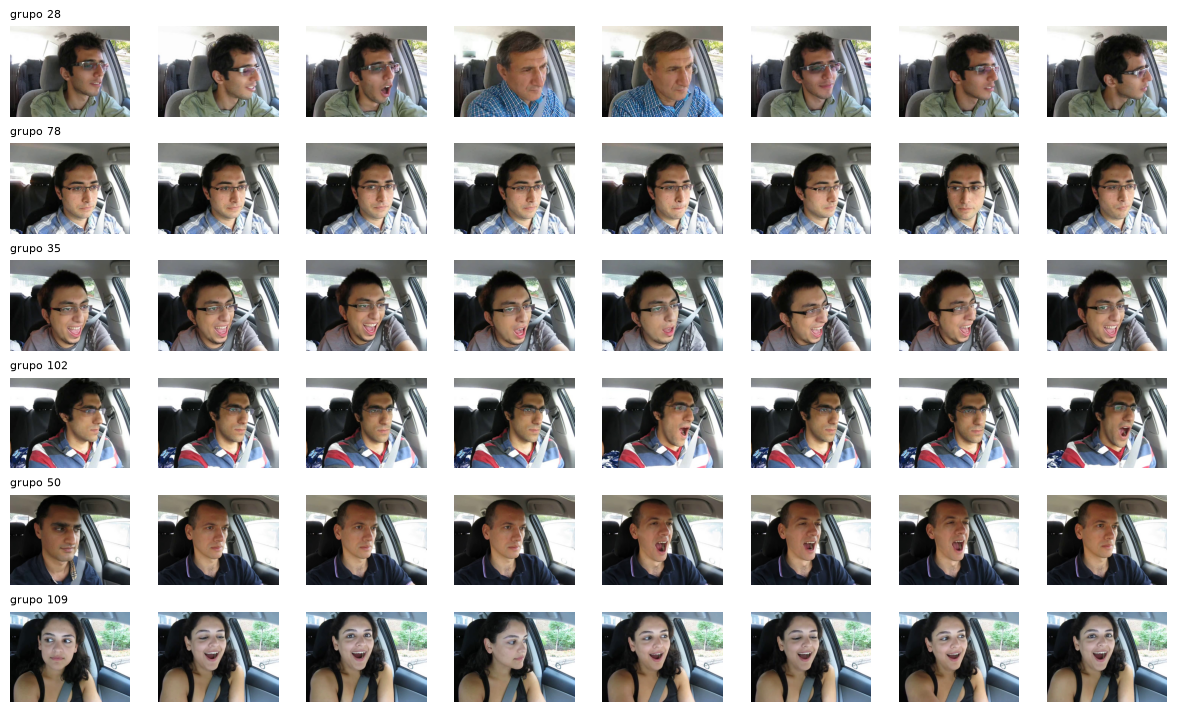

In [4]:
# Grupos de ejemplo
rng = np.random.default_rng(1)
grandes = []
for g, n in tamanos.items():
    if n >= 8:
        grandes.append(g)

ejemplo = rng.choice(grandes, 6, replace=False)
fig, axs = plt.subplots(len(ejemplo), 8, figsize=(12, 1.2 * len(ejemplo)))

for fila, g in enumerate(ejemplo):
    idx = rng.choice(np.where(grupos == g)[0], 8, replace=False)
    for col, i in enumerate(idx):
        orig = cv2.imread(os.path.join(ORIGINALES, CLASES[y[i]], os.path.basename(rutas[i])))
        axs[fila, col].imshow(cv2.cvtColor(orig, cv2.COLOR_BGR2RGB))
        axs[fila, col].axis('off')
        
    axs[fila, 0].set_title(f'grupo {g}', loc='left', fontsize=8)

plt.tight_layout()
plt.savefig(f'{FIGURAS}/boca_grupos.png', dpi=100)
plt.show()

---

## 2. Descriptores HOG vs LBP

Con la boca abierta aparece una zona oscura grande, equivalente al interior de la boca y bordes verticales de los labios y los dientes. 

* HOG captura esos bordes
* LBP la textura de dientes y labios.

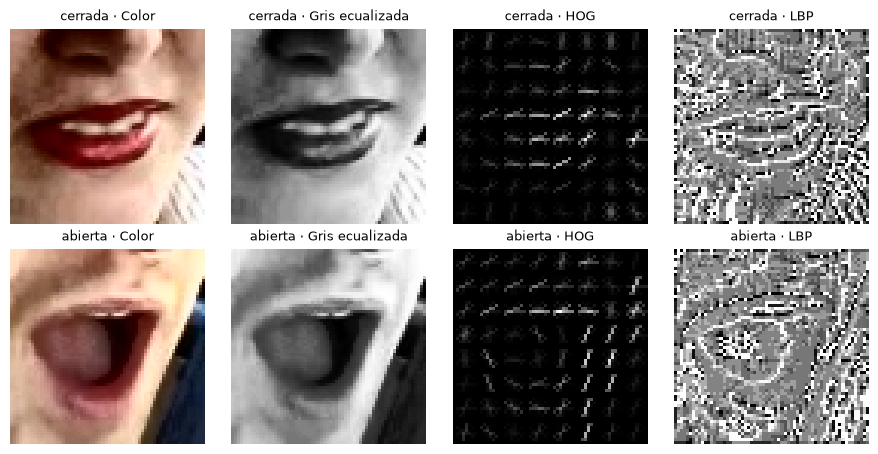

In [ ]:
fig, axs = plt.subplots(2, 4, figsize=(9, 4.6))

for fila, etiqueta in enumerate([0, 1]):
    i = np.where(y == etiqueta)[0][40]
    _, vis_hog = hog(X[i], orientations=9, pixels_per_cell=(8, 8), cells_per_block=(2, 2), visualize=True)
    lbp = local_binary_pattern(X[i], 8, 1, method='nri_uniform')
    imgs = [cv2.cvtColor(X_color[i], cv2.COLOR_BGR2RGB), X[i], vis_hog, lbp]
    
    for ax, im, titulo in zip(axs[fila], imgs, ['Color', 'Gris ecualizada', 'HOG', 'LBP']):
        if im.ndim == 3:
            ax.imshow(im)
        else:
            ax.imshow(im, cmap='gray')
        ax.set_title(f'{CLASES[etiqueta]} · {titulo}', fontsize=9)
        ax.axis('off')

plt.tight_layout()
plt.savefig(f'{FIGURAS}/boca_descriptores.png', dpi=120)
plt.show()

---

## 3. Validación cruzada k-fold agrupada por persona

Los descriptores HOG y LBP se calculan sobre la imagen en gris ecualizada. La CNN recibe la imagen **en color**, porque el color del interior de la boca, los labios y los dientes puede ayudar, y se entrena 30 épocas con aumento de datos.

* Métricas respecto a la clase **abierta**: una precisión baja haría que la nave disparase sola; un recall bajo, que no dispare cuando el jugador abre la boca.

In [5]:
METODOS = ['Píxeles + KNN', 'HOG + SVM', 'LBP + SVM', 'CNN']
res = kfold_agrupado(X, y, grupos, METODOS, k=5, X_cnn=X_color)
print()
tabla_resultados(res)

Fold 1: Píxeles + KNN F1=0.895 | HOG + SVM F1=0.957 | LBP + SVM F1=0.957 | CNN F1=0.840
Fold 2: Píxeles + KNN F1=0.932 | HOG + SVM F1=0.996 | LBP + SVM F1=0.996 | CNN F1=0.912
Fold 3: Píxeles + KNN F1=0.935 | HOG + SVM F1=0.993 | LBP + SVM F1=1.000 | CNN F1=0.935
Fold 4: Píxeles + KNN F1=0.919 | HOG + SVM F1=0.993 | LBP + SVM F1=0.986 | CNN F1=0.879
Fold 5: Píxeles + KNN F1=0.926 | HOG + SVM F1=0.976 | LBP + SVM F1=0.976 | CNN F1=0.952

Método                 Accuracy       Precisión          Recall              F1
Píxeles + KNN     0.926 ± 0.013   0.973 ± 0.024   0.876 ± 0.026   0.921 ± 0.014
HOG + SVM         0.983 ± 0.014   0.991 ± 0.012   0.975 ± 0.018   0.983 ± 0.015
LBP + SVM         0.983 ± 0.015   0.990 ± 0.010   0.976 ± 0.022   0.983 ± 0.016
CNN               0.905 ± 0.037   0.914 ± 0.083   0.911 ± 0.101   0.904 ± 0.040


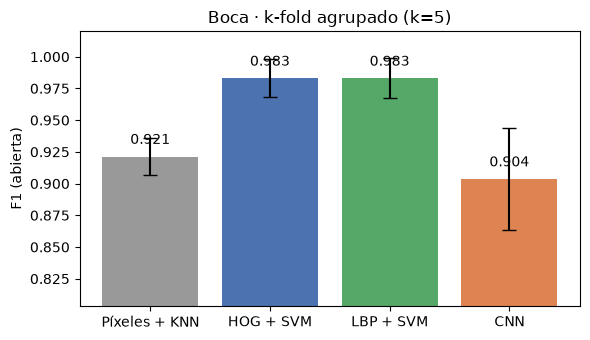

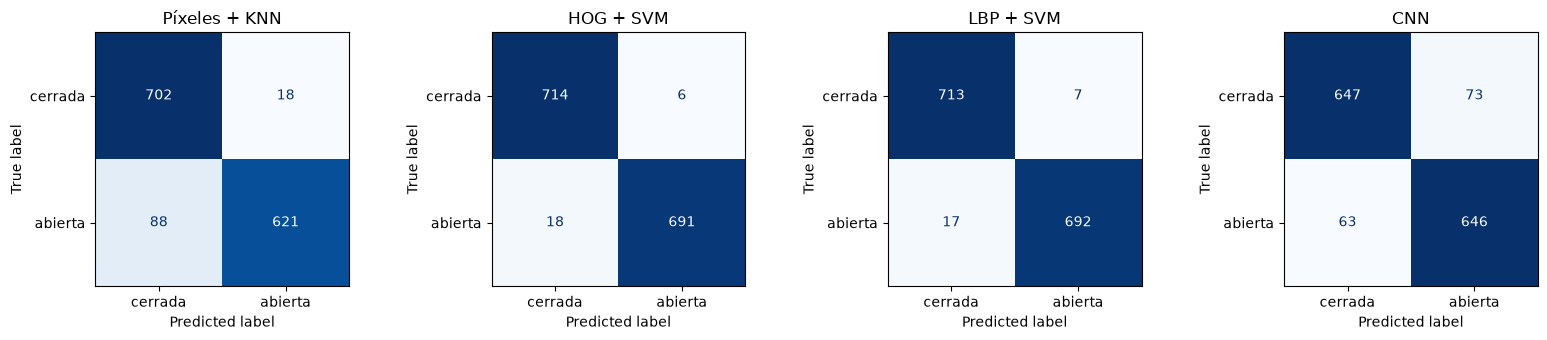

In [ ]:
f1, f1_std = [], []

for m in METODOS:
    media, desviacion = f1_medio(res, m)
    f1.append(media)
    f1_std.append(desviacion)

plt.figure(figsize=(6, 3.5))
plt.bar(METODOS, f1, yerr=f1_std, capsize=5, color=['#999999', '#4C72B0', '#55A868', '#DD8452'])

for i, v in enumerate(f1):
    plt.text(i, v + 0.01, f'{v:.3f}', ha='center')

plt.ylim(min(f1) - 0.1, 1.02)
plt.ylabel('F1 (abierta)')
plt.title('Boca · k-fold agrupado (k=5)')
plt.tight_layout()
plt.savefig(f'{FIGURAS}/boca_kfold_f1.png', dpi=120)
plt.show()

fig, axs = plt.subplots(1, len(METODOS), figsize=(4 * len(METODOS), 3.5))

for ax, m in zip(axs, METODOS):
    ConfusionMatrixDisplay(res[m]['cm'], display_labels=CLASES).plot(ax=ax, colorbar=False, cmap='Blues')
    ax.set_title(m)
    
plt.tight_layout()
plt.savefig(f'{FIGURAS}/boca_kfold_confusion.png', dpi=120)
plt.show()

---

## 4. k-fold sin agrupar frente a agrupado

Para comprobar que la agrupación importa, se repite el k-fold con los métodos clásicos **repartiendo las imágenes al azar** (cada imagen es su propio grupo), como se haría con un `StratifiedKFold` normal.

Método           F1 al azar  F1 agrupado  Diferencia
Píxeles + KNN         0.965        0.921      +0.043
HOG + SVM             0.989        0.983      +0.006
LBP + SVM             0.991        0.983      +0.008


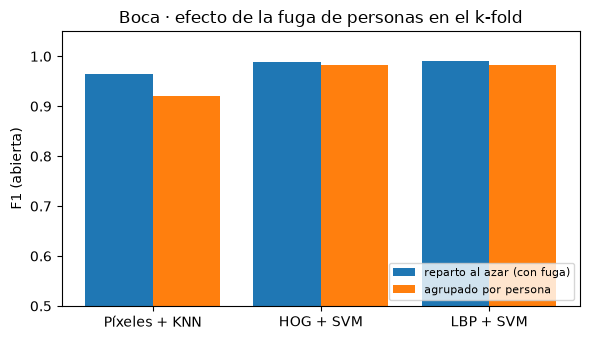

In [ ]:
METODOS_FUGA = ['Píxeles + KNN', 'HOG + SVM', 'LBP + SVM']

res_azar = kfold_agrupado(X, y, np.arange(len(y)), METODOS_FUGA, k=5, verbose=False)

print(f"{'Método':15s} {'F1 al azar':>11s} {'F1 agrupado':>12s} {'Diferencia':>11s}")

for m in METODOS_FUGA:
    a, g = f1_medio(res_azar, m)[0], f1_medio(res, m)[0]
    print(f'{m:15s} {a:11.3f} {g:12.3f} {a - g:+11.3f}')

f1_azar, f1_agrupado = [], []

for m in METODOS_FUGA:
    f1_azar.append(f1_medio(res_azar, m)[0])
    f1_agrupado.append(f1_medio(res, m)[0])

xs = np.arange(len(METODOS_FUGA))

plt.figure(figsize=(6, 3.5))
plt.bar(xs - 0.2, f1_azar, 0.4, label='reparto al azar (con fuga)')
plt.bar(xs + 0.2, f1_agrupado, 0.4, label='agrupado por persona')
plt.xticks(xs, METODOS_FUGA)
plt.ylim(0.5, 1.05)
plt.ylabel('F1 (abierta)')
plt.title('Boca · efecto de la fuga de personas en el k-fold')
plt.legend(fontsize=8, loc='lower right')
plt.tight_layout()
plt.savefig(f'{FIGURAS}/boca_fuga_kfold.png', dpi=120)
plt.show()

---

## 5. Comparación con MediaPipe `jawOpen`

MediaPipe calcula, además de los landmarks, unas 50 puntuaciones de expresión (*blendshapes*) entre 0 y 1.

* `jawOpen` indica cuánto está abierta la mandíbula. Para usarlo como clasificador hace falta un **umbral**: en cada fold se elige el umbral que maximiza el F1 en las imágenes de entrenamiento y se evalúa en las de test, con **los mismos folds** que los modelos anteriores.

En el juego MediaPipe se ejecuta igualmente para recortar la boca, así que esta puntuación sale "gratis". Comparar con ella permite saber si el modelo entrenado aporta algo frente a lo que ya existe.

Imágenes sin blendshapes: 0


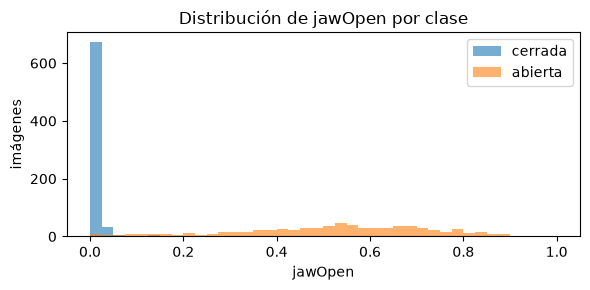

In [ ]:
import mediapipe as mp

opciones = mp.tasks.vision.FaceLandmarkerOptions(
    base_options=mp.tasks.BaseOptions(model_asset_path='face_landmarker.task'),
    running_mode=mp.tasks.vision.RunningMode.IMAGE,
    num_faces=1, output_face_blendshapes=True)

jaw = np.full(len(y), np.nan)

with mp.tasks.vision.FaceLandmarker.create_from_options(opciones) as detector:
    for i, r in enumerate(rutas):
        orig = cv2.imread(os.path.join(ORIGINALES, CLASES[y[i]], os.path.basename(r)))
        res_mp = detector.detect(mp.Image(image_format=mp.ImageFormat.SRGB,
                                          data=cv2.cvtColor(orig, cv2.COLOR_BGR2RGB)))
        if res_mp.face_blendshapes:
            for c in res_mp.face_blendshapes[0]:
                if c.category_name == 'jawOpen':
                    jaw[i] = c.score
                    break

print('Imágenes sin blendshapes:', int(np.isnan(jaw).sum()))
jaw = np.nan_to_num(jaw, nan=0.0)

plt.figure(figsize=(6, 3))

for etiqueta in [0, 1]:
    plt.hist(jaw[y == etiqueta], bins=40, range=(0, 1), alpha=0.6, label=CLASES[etiqueta])

plt.xlabel('jawOpen'); plt.ylabel('imágenes'); plt.legend()
plt.title('Distribución de jawOpen por clase')
plt.tight_layout()
plt.savefig(f'{FIGURAS}/boca_jawopen_hist.png', dpi=120)
plt.show()

In [ ]:
def mejor_umbral(puntos, etiquetas):
    """Umbral entre 0,01 y 0,99 que da el mayor F1 con las imágenes de entrenamiento."""
    mejor, mejor_f1 = None, -1

    for u in np.linspace(0.01, 0.99, 99):
        f1 = metricas(etiquetas, (puntos >= u).astype(int))['f1']
        if f1 > mejor_f1:
            mejor, mejor_f1 = u, f1
    return mejor

skf = StratifiedGroupKFold(n_splits=5, shuffle=True, random_state=0)   # mismos folds que kfold_agrupado
res_mp_folds, umbrales = [], []

for tr, te in skf.split(X, y, grupos):
    u = mejor_umbral(jaw[tr], y[tr])
    umbrales.append(u)
    res_mp_folds.append(metricas(y[te], (jaw[te] >= u).astype(int)))

res['MediaPipe jawOpen'] = {'folds': res_mp_folds}
print('Umbrales elegidos en cada fold:', np.round(umbrales, 2))
res_tabla = {}

for m in METODOS + ['MediaPipe jawOpen']:
    res_tabla[m] = res[m]
tabla_resultados(res_tabla)

Umbrales elegidos en cada fold: [0.05 0.06 0.06 0.06 0.08]
Método                 Accuracy       Precisión          Recall              F1
Píxeles + KNN     0.926 ± 0.013   0.973 ± 0.024   0.876 ± 0.026   0.921 ± 0.014
HOG + SVM         0.983 ± 0.014   0.991 ± 0.012   0.975 ± 0.018   0.983 ± 0.015
LBP + SVM         0.983 ± 0.015   0.990 ± 0.010   0.976 ± 0.022   0.983 ± 0.016
CNN               0.905 ± 0.037   0.914 ± 0.083   0.911 ± 0.101   0.904 ± 0.040
MediaPipe jawOpen   0.980 ± 0.013   0.983 ± 0.020   0.976 ± 0.022   0.980 ± 0.013


---

## 6. Modelos finales y latencia

Se entrenan los modelos con todas las imágenes y se mide el tiempo de clasificar **un recorte de boca** (incluyendo el descriptor), que es lo que se hará en cada fotograma del juego.

In [ ]:
modelos = {
    'HOG + SVM': ModeloGesto.entrena('hog', X, y, TAM, True, CLASES, ecualizar=ECUALIZAR),
    'LBP + SVM': ModeloGesto.entrena('lbp', X, y, TAM, True, CLASES, ecualizar=ECUALIZAR),
    'CNN': ModeloGesto.entrena('cnn', X_color, y, TAM, False, CLASES, ecualizar=ECUALIZAR),
}

recortes_bgr = []

for r in rutas[::5][:300]:
    recortes_bgr.append(cv2.imread(r))

latencias = {}

for n, mg in modelos.items():
    latencias[n] = mide_latencia(mg, recortes_bgr)
    
for n, ms in latencias.items():
    print(f'{n:12s} {ms:6.2f} ms por recorte de boca')

HOG + SVM      2.36 ms por recorte de boca
LBP + SVM      2.43 ms por recorte de boca
CNN            1.05 ms por recorte de boca


---

## 7. Modelo elegido

**Criterio de elección**: entre los modelos **entrenados por nosotros**, el de mayor F1 en el k-fold agrupado por persona. Si dos modelos quedan a menos de 0,005 de F1 (diferencia menor que la variación entre folds), se elige el más rápido. 

> MediaPipe `jawOpen` se muestra como referencia, pero no se elige porque la práctica pide un modelo entrenado propio.

- `figuras/boca_resumen.png`: comparación de métodos con el elegido resaltado con una estrella.
- `resultados/boca_resumen.md` y `.json`: tabla, modelo elegido y motivo.

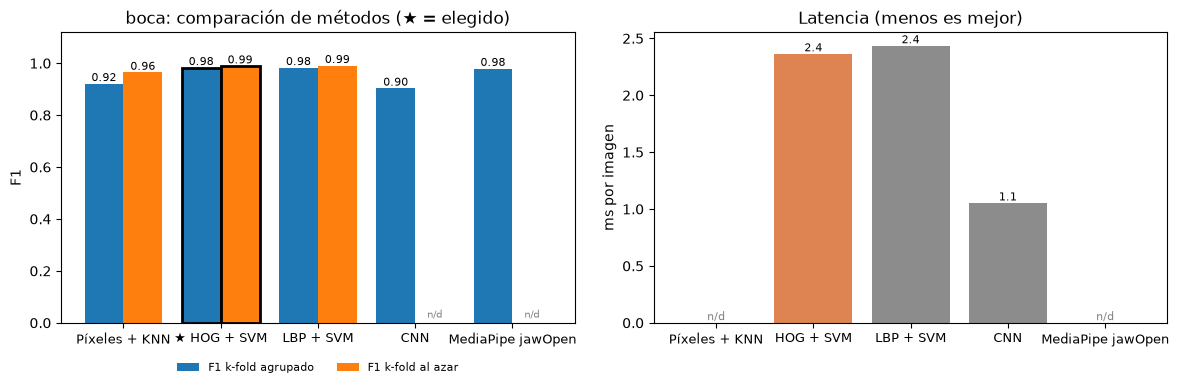

## Modelo de boca

| Método | F1 k-fold agrupado | F1 k-fold al azar | ms por imagen |
|---|---|---|---|
| Píxeles + KNN | 0.921 | 0.965 | — |
| **HOG + SVM** ★ | 0.983 | 0.989 | 2.4 |
| LBP + SVM | 0.983 | 0.991 | 2.4 |
| CNN | 0.904 | — | 1.1 |
| MediaPipe jawOpen | 0.980 | — | — |

**Modelo elegido:** HOG + SVM

**Motivo:** Mayor F1 en el k-fold agrupado por persona entre los modelos entrenados: 0.983 (empatado a menos de 0,005 con LBP + SVM, se elige por ser el más rápido), con 2.4 ms por recorte. Como referencia, MediaPipe jawOpen sin entrenar obtiene 0.980.

Guardado: figuras\boca_resumen.png, resultados/boca_resumen.md y .json
Modelos guardados en modelos/  ->  el juego usará modelos/boca_hog


In [ ]:
# F1 medio en el k-fold de cada método
f1k = {}
for m in list(modelos) + ['Píxeles + KNN', 'MediaPipe jawOpen']:
    f1k[m] = f1_medio(res, m)[0]

# Mejor F1 entre los modelos entrenados
mejor_f1 = -1
for m in modelos:
    if f1k[m] > mejor_f1:
        mejor_f1 = f1k[m]

# Los que se quedan a menos de 0,005 del mejor (empate)
candidatos = []
for m in modelos:
    if mejor_f1 - f1k[m] < 0.005:
        candidatos.append(m)

# El más rápido
elegido, ms_elegido = None, float('inf')

for m in candidatos:
    if latencias[m] < ms_elegido:
        elegido, ms_elegido = m, latencias[m]

filas = [{'Método': 'Píxeles + KNN', 'F1 k-fold agrupado': f1k['Píxeles + KNN'],
          'F1 k-fold al azar': f1_medio(res_azar, 'Píxeles + KNN')[0], 'ms': None}]

for m in modelos:
    if m in res_azar:
        f1_azar_m = f1_medio(res_azar, m)[0]
    else:
        f1_azar_m = None
    filas.append({'Método': m, 'F1 k-fold agrupado': f1k[m],
                  'F1 k-fold al azar': f1_azar_m, 'ms': latencias[m]})
filas.append({'Método': 'MediaPipe jawOpen', 'F1 k-fold agrupado': f1k['MediaPipe jawOpen'],
              'F1 k-fold al azar': None, 'ms': None})

if len(candidatos) > 1:
    otros = []
    for c in candidatos:
        if c != elegido:
            otros.append(c)
    texto_empate = (f" (empatado a menos de 0,005 con {', '.join(otros)}, "
                    f"se elige por ser el más rápido)")
else:
    texto_empate = ''
motivo = (f"Mayor F1 en el k-fold agrupado por persona entre los modelos entrenados: {f1k[elegido]:.3f}"
          f"{texto_empate}, con {latencias[elegido]:.1f} ms por recorte. "
          f"Como referencia, MediaPipe jawOpen sin entrenar obtiene {f1k['MediaPipe jawOpen']:.3f}.")

guarda_resumen('boca', filas, elegido, motivo, ['F1 k-fold agrupado', 'F1 k-fold al azar'])

for n, mg in modelos.items():
    mg.guarda(f'modelos/boca_{mg.tipo}')
print('Modelos guardados en modelos/  ->  el juego usará modelos/boca_' + modelos[elegido].tipo)

---

## 8. Facilidad de uso y coste

Comparamos los modelos clásicos y las redes neuronales no solo por sus resultados, sino también por su **facilidad de uso** y su **rapidez**. 

Para cada método se recoge:

- **Tiempo de entrenamiento** medio por fold, incluida la búsqueda en rejilla de la SVM.
- **Tiempo de predicción** por imagen del modelo final, que es lo que importa en el juego.
- **Tamaño** del modelo guardado.
- **Qué hay que ajustar** para usarlo.

Se guarda en `resultados/boca_facilidad.md` y `figuras/boca_facilidad.png`.

## Facilidad de uso y coste: boca

| Método | Entrenamiento por fold (s) | Predicción (ms/imagen) | Tamaño (MB) | Qué hay que ajustar | Observaciones |
|---|---|---|---|---|---|
| Píxeles + KNN | 0.1 | — | — | k (vecinos) | No entrena: guarda todas las imágenes y compara con todas al predecir. |
| HOG + SVM | 8.5 | 2.4 | 6.63 | celdas, orientaciones, bloques + C y gamma (rejilla) | Hay que diseñar el descriptor; la búsqueda en rejilla de la SVM multiplica el tiempo de entrenamiento. |
| LBP + SVM | 3.6 | 2.4 | 5.08 | celdas, vecinos, radio, tipo de patrón + C y gamma (rejilla) | Igual que HOG; el descriptor es más lento de calcular. |
| CNN | 13.1 | 1.1 | 0.39 | arquitectura, épocas, lote, optimizador, aumento de datos | No hay que diseñar descriptores, pero sí la red; necesita TensorFlow. Su tiempo de entrenamiento depende de las épocas, no del número de vectores soporte, y en CPU es similar al de la SVM con búsqueda en rejilla. |
| MediaPipe jawOpen | 0.0 | — | — | solo el umbral | S

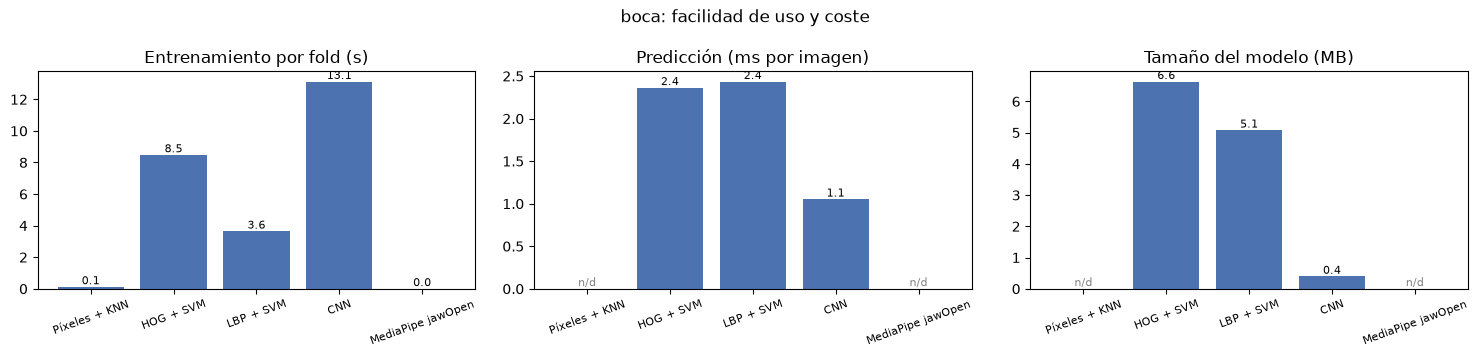

In [12]:
from utilidades_gestos import tabla_facilidad
facilidad = tabla_facilidad('boca', res, latencias, referencias={'MediaPipe jawOpen': None})

---

## 9. Conclusiones

| Método | F1 k-fold agrupado | F1 k-fold al azar | ms por recorte |
|---|---|---|---|
| Píxeles + KNN | 0,921 ± 0,014 | 0,965 | — |
| **HOG + SVM** ★ | **0,983 ± 0,015** | 0,989 | 2,4 |
| LBP + SVM | 0,983 ± 0,016 | 0,991 | 2,4 |
| CNN (color, con aumento) | 0,904 ± 0,040 | — | 1,1 |
| MediaPipe `jawOpen` (sin entrenar) | 0,980 ± 0,013 | — | — |

La comparación final y el modelo elegido quedan guardados en `figuras/boca_resumen.png` y `resultados/boca_resumen.md`.

1. **Distinguir un bostezo de una boca cerrada es una tarea fácil** para los descriptores clásicos: HOG + SVM y LBP + SVM aciertan el 98 % con personas que no han visto. La boca abierta crea una zona oscura grande y bordes muy marcados que HOG y LBP capturan bien.
2. **La CNN queda por detrás** (0,904) y es la menos estable entre folds (± 0,04). Con solo unas 1.100 imágenes de entrenamiento por fold, una red entrenada desde cero aprende peor que una SVM sobre buenos descriptores. Al contrario que en los ojos, aquí no hay un test externo en el que la CNN pueda demostrar mejor generalización.
3. **Agrupar por persona importa, aunque aquí menos de lo esperado**: con el reparto al azar el F1 sube +0,04 en píxeles + KNN (que casi "memoriza" a las personas) y solo +0,01 en HOG y LBP. Aun así, el agrupado es la estimación honesta.
4. **MediaPipe `jawOpen` sin entrenar obtiene prácticamente lo mismo** (0,980) que el mejor modelo entrenado. El histograma lo explica, las bocas cerradas dan `jawOpen` casi nulo (< 0,05), mientras que los bostezos se reparten entre 0,1 y 0,9. Por eso el umbral óptimo es bajo (≈ 0,06); con un umbral "intuitivo" de 0,5 se perdería cerca de la mitad de las bocas abiertas. 
    *  **Limitación**: las bocas "abiertas" del dataset son bostezos, mucho más abiertos que una boca abierta normal al jugar. En la prueba con la webcam habrá que comprobar que el modelo también detecta una apertura moderada.
5. **Latencia**: todos tardan entre 1 y 2,5 ms por recorte, así que cualquiera es válido para el juego.

6. **Facilidad de uso y coste**: la CNN es la más lenta de entrenar en este conjunto pequeño (13 s por fold frente a 4–9 s de las SVM), pero la más rápida al predecir (1,1 ms frente a 2,4 ms) y la más ligera (0,39 MB frente a 5–6,6 MB). 
    * MediaPipe `jawOpen` no necesita entrenamiento ni archivos extra, porque ya se calcula al obtener los landmarks: solo hay que elegir el umbral.

> El modelo elegido ha sido **HOG + SVM** (`modelos/boca_hog`). Empata en F1 con LBP + SVM y es algo más rápido.

* **Comprobación en directo**: con la webcam, HOG + SVM con el recorte de la boca **sin girar** disparaba en el 21 % de los fotogramas con la boca cerrada (46 % con la cabeza inclinada). Al **girar el recorte** para alinear la boca, los falsos disparos bajaron al 1,6 % (3,7 % con la cabeza inclinada), detectando el 95 % de las aperturas grandes: fue la mejor de las seis variantes probadas. Por eso **el juego usa HOG + SVM**, el mismo modelo elegido por k-fold, **con el recorte girado**.

---